In [1]:
import pandas as pd

columns = [
    'engine_displacement',
    'horsepower',
    'vehicle_weight',
    'model_year',
    'fuel_efficiency_mpg',
]

df = pd.read_csv('car_fuel_efficiency_2026.csv', usecols=columns)
df.head()
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]

def rmse(y, y_pred):
    return np.sqrt(((y - y_pred) ** 2).mean())

def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns


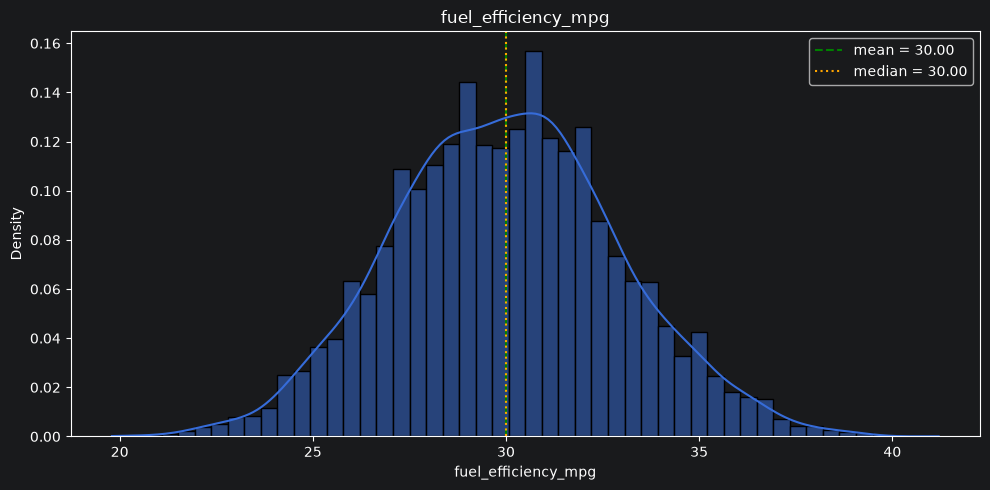

In [3]:
mpg = df.fuel_efficiency_mpg.dropna()

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(mpg, bins=50, kde=True, stat='density', ax=ax)
ax.axvline(mpg.mean(), color='green', linestyle='--', label=f'mean = {mpg.mean():.2f}')
ax.axvline(mpg.median(), color='orange', linestyle=':', label=f'median = {mpg.median():.2f}')
ax.set_title('fuel_efficiency_mpg')
ax.legend()
plt.tight_layout()

In [4]:
pd.Series({
    'skew': mpg.skew(),
    'kurtosis': mpg.kurtosis(),
    'min': mpg.min(),
    'max': mpg.max(),
    'below_p01': (mpg < mpg.quantile(0.01)).sum(),
    'above_p99': (mpg > mpg.quantile(0.99)).sum(),
})

skew          0.080804
kurtosis     -0.070326
min          19.800000
max          41.200000
below_p01    92.000000
above_p99    94.000000
dtype: float64

In [5]:
features = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']
missing = df[features].isna().sum()
missing

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
dtype: int64

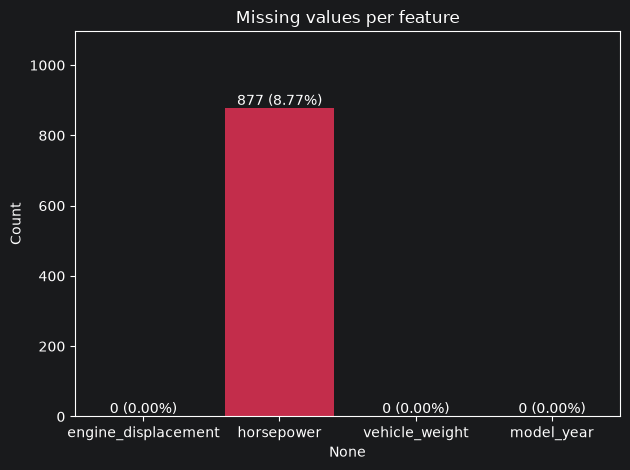

In [6]:
sns.barplot(x=missing.index, y=missing.values, color='crimson')
for i, v in enumerate(missing.values):
    plt.text(i, v + 10, f'{v} ({v / len(df):.2%})', ha='center')
plt.title('Missing values per feature')
plt.ylabel('Count')
plt.ylim(0, missing.max() * 1.25)
plt.tight_layout()

In [7]:
df.horsepower.median()

np.float64(254.0)

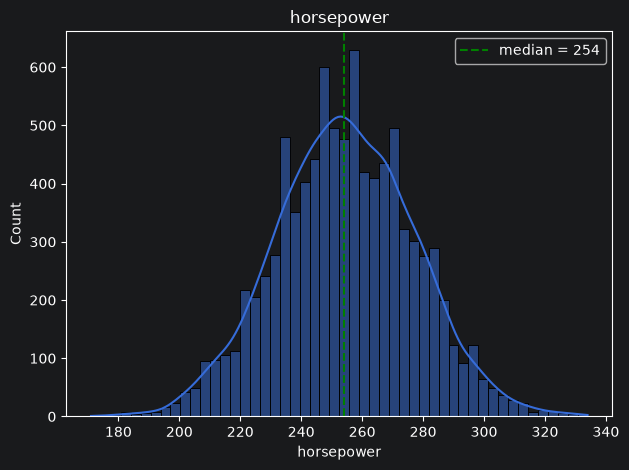

In [8]:
sns.histplot(df.horsepower.dropna(), bins=50, kde=True)
plt.axvline(df.horsepower.median(), color='green', linestyle='--', label=f'median = {df.horsepower.median():.0f}')
plt.title('horsepower')
plt.legend()
plt.tight_layout()

In [9]:
import numpy as np

np.random.seed(42)
n = len(df)
idx = np.arange(n)
np.random.shuffle(idx)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

df_train = df.iloc[idx[:n_train]].reset_index(drop=True)
df_val = df.iloc[idx[n_train:n_train+n_val]].reset_index(drop=True)
df_test = df.iloc[idx[n_train+n_val:]].reset_index(drop=True)

y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values

base = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']


def train_lin(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]


def rmse(y, y_pred):
    return np.sqrt(((y - y_pred) ** 2).mean())


# Fill with 0
X_train0 = df_train[base].fillna(0).values
w00, w0 = train_lin(X_train0, y_train)
X_val0 = df_val[base].fillna(0).values
yp0 = w00 + X_val0.dot(w0)
r0 = rmse(y_val, yp0)

# Fill with mean (training only)
hp_mean = df_train.horsepower.mean()
X_trainm = df_train[base].copy()
X_trainm['horsepower'] = X_trainm.horsepower.fillna(hp_mean)
X_trainm = X_trainm.values
w0m, wm = train_lin(X_trainm, y_train)
X_valm = df_val[base].copy()
X_valm['horsepower'] = X_valm.horsepower.fillna(hp_mean)
X_valm = X_valm.values
ypm = w0m + X_valm.dot(wm)
rm = rmse(y_val, ypm)

print('fill with 0:', round(r0, 3))
print('fill with mean:', round(rm, 3))
print('better:', 'mean' if rm < r0 else ('zero' if r0 < rm else 'equal'))

fill with 0: 2.205
fill with mean: 2.202
better: mean


In [10]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]


best_r = None
best_s = float('inf')
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    X_tr = df_train[base].fillna(0).values  # fill NAs with 0
    X_val = df_val[base].fillna(0).values
    w0, w = train_linear_regression_reg(X_tr, y_train, r=r)
    y_pred = w0 + X_val.dot(w)
    s = rmse(y_val, y_pred)
    print(f'r={r}: {s:.4f}')
    if s < best_s - 1e-12 or (abs(s - best_s) < 1e-12 and best_r is None):
        best_s, best_r = s, r
    elif abs(s - best_s) < 1e-12 and best_r is not None and r < best_r:
        best_s, best_r = s, r

print(f'\nBest: r={best_r}, RMSE={best_s:.4f}')

r=0: 2.2053
r=0.01: 2.2058
r=0.1: 2.2241
r=1: 2.3492
r=5: 2.4094
r=10: 2.4195
r=100: 2.4292

Best: r=0, RMSE=2.2053


In [11]:
base = ['engine_displacement','horsepower','vehicle_weight','model_year']
scores = []
for seed in [0,1,2,3,4,5,6,7,8,9]:
    n = len(df)
    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)
    n_val = int(n*0.2); n_test = int(n*0.2); n_train = n-n_val-n_test
    df_train_s = df.iloc[idx[:n_train]].reset_index(drop=True)
    df_val_s = df.iloc[idx[n_train:n_train+n_val]].reset_index(drop=True)
    y_train_s = df_train_s.fuel_efficiency_mpg.values
    y_val_s = df_val_s.fuel_efficiency_mpg.values
    Xtr = df_train_s[base].fillna(0).values
    Xv = df_val_s[base].fillna(0).values
    w0,w = train_linear_regression_reg(Xtr,y_train_s,r=0)
    y_pred = w0 + Xv.dot(w)
    scores.append(rmse(y_val_s,y_pred))
print('std:', round(np.std(scores),3))


std: 0.029


In [12]:
seed = 9
n = len(df)
np.random.seed(seed)
idx = np.arange(n)
np.random.shuffle(idx)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test
df_train_f = df.iloc[idx[:n_train]].reset_index(drop=True)
df_val_f = df.iloc[idx[n_train:n_train+n_val]].reset_index(drop=True)
df_test_f = df.iloc[idx[n_train+n_val:]].reset_index(drop=True)
y_train_f = df_train_f.fuel_efficiency_mpg.values
y_val_f = df_val_f.fuel_efficiency_mpg.values
y_test_f = df_test_f.fuel_efficiency_mpg.values

df_full = pd.concat([df_train_f, df_val_f]).reset_index(drop=True)
y_full = np.concatenate([y_train_f, y_val_f])

X_full = df_full[base].fillna(0).values
X_test_f = df_test_f[base].fillna(0).values
w0, w = train_linear_regression_reg(X_full, y_full, r=0.001)
y_pred = w0 + X_test_f.dot(w)
print(round(rmse(y_test_f, y_pred), 3))

2.236
